# Stage 0b - Preprocess NFP Frames and Figure Out Scan Positions

## Read from `data_ca.h5`

In [2]:
# --- paths ----------------------------------------------------------
# From config_step0.conf, which holds every path for the NFP scan.
# Edit that file, not this cell.
from holotomocupy.config import parse_args_coded_step0
_cfg = parse_args_coded_step0('config_step0.conf')
WITH_CA = _cfg.path   # processed data for this sample


In [3]:
import numpy as np
import cupy as cp
import cupyx.scipy.ndimage as ndimage
import h5py
import matplotlib.pyplot as plt
%matplotlib inline

path_out = WITH_CA + '/'
fname_ca = f'{WITH_CA}/data_nfp.h5'

with h5py.File(fname_ca, 'r') as fid:
    data   = fid['/exchange/data'][:]      .astype('float32')   # raw NFP data, (324, 2048, 2048)
    ref    = fid['/exchange/data_white'][:].astype('float32')   # raw flat-field data, (21,  2048, 2048)
    dark   = fid['/exchange/data_dark'][:] .astype('float32')   # raw dark field data, (20,  2048, 2048)
    z1            = float(fid['/exchange/z1'][0])
    detector_pixelsize   = float(fid['/exchange/detector_pixelsize'][0])
    focusdetectordistance = float(fid['/exchange/focusdetectordistance'][0])
    energy        = float(fid['/exchange/energy'][0])
    voxelsize     = float(fid['/exchange/voxelsize'][0])

# Recompute derived geometry
wavelength = 1.24e-9 / energy
z2         = focusdetectordistance - z1
distances  = (z1 * z2) / focusdetectordistance
[npos, n, _] = data.shape

print(f'z1            = {z1*1e3:.4f} mm')
print(f'z2            = {z2*1e3:.4f} mm')
print(f'distances     = {distances*1e3:.4f} mm  (effective Fresnel propagation)')
print(f'voxelsize     = {voxelsize*1e9:.3f} nm')
print(f'data  : {data.shape}  dtype={data.dtype}  range=[{data.min():.0f}, {data.max():.0f}]')
print(f'ref   : {ref.shape}   dtype={ref.dtype}   range=[{ref.min():.0f}, {ref.max():.0f}]')
print(f'dark  : {dark.shape}  dtype={dark.dtype}  range=[{dark.min():.0f}, {dark.max():.0f}]')
print(f'npos={npos}, n={n}')

z1            = -19.0360 mm
z2            = 1299.0360 mm
distances     = -19.3191 mm  (effective Fresnel propagation)
voxelsize     = 45.173 nm
data  : (324, 2048, 2048)  dtype=float32  range=[1400, 65535]
ref   : (21, 2048, 2048)   dtype=float32   range=[1676, 65535]
dark  : (20, 2048, 2048)  dtype=float32  range=[845, 65535]
npos=324, n=2048


## Preprocessing

In [4]:
def remove_outliers(data, dezinger, dezinger_threshold):
    """GPU dezinger: replace outlier pixels with 3×3 median.
    
    data              : (nframes, ny, nx) float32 — input array (modified in-place copy)
    dezinger          : int    — median filter half-width (3 → 3×3 kernel)
    dezinger_threshold: float  — relative threshold (0.8 → flag if |px-med|>0.8·med)
    Returns array with outliers replaced by local median.
    """
    res = data.copy()
    w   = [dezinger, dezinger]
    for k in range(data.shape[0]):
        data0 = cp.array(data[k])                              # CPU→GPU
        fdata = ndimage.median_filter(data0, w)                # GPU 3×3 median
        res[k] = np.where(
            np.abs(data0 - fdata) > fdata * dezinger_threshold,
            fdata, data0
        ).get()                                                # GPU→CPU
    return res


# Steps 1–2: dark averaging and subtraction
dark = np.mean(dark, axis=0)   # (2048, 2048)  pixel-wise mean of 20 darks
ref  = np.mean(ref,  axis=0)   # (2048, 2048)  pixel-wise mean of 21 refs
data -= dark
ref  -= dark

# Step 3: clip to non-negative
data[data < 0] = 0
ref [ref  < 0] = 0

# Step 4: dead-pixel repair
# One detector column cluster at indices `[1320//3 : 1320//3+25//3, 890//3 : 890//3+25//3]`
# has a known defect. It is replaced by the adjacent good region at `[1280//3 : ...]`.
# The `//3` arises from 3× spatial binning relative to the beamline control system's
# 6144 × 6144 coordinate frame.
data[:, 1320//3 : 1320//3 + 25//3, 890//3 : 890//3 + 25//3] = \
    data[:, 1280//3 : 1280//3 + 25//3, 890//3 : 890//3 + 25//3]
ref [   1320//3 : 1320//3 + 25//3, 890//3 : 890//3 + 25//3] = \
    ref [   1280//3 : 1280//3 + 25//3, 890//3 : 890//3 + 25//3]

# Step 5: dezinger on GPU 
data = remove_outliers(data, 3, 0.8)
ref  = remove_outliers(ref[None], 3, 0.8)[0]   # add/remove batch dim

# Step 6: flat-field normalisation (scalar)
ref_mean = float(np.mean(ref))
data /= ref_mean   # normalised NFP frames
ref  /= ref_mean   # ref → ≈ 1.0

# Step 7: NaN fill
data[np.isnan(data)] = 1
ref [np.isnan(ref)]  = 1

print(f'\nAfter preprocessing:')
print(f'  data : {data.shape}  range=[{data.min():.4f}, {data.max():.4f}]')
print(f'  ref  : {ref.shape}   range=[{ref.min():.4f},  {ref.max():.4f}]')


After preprocessing:
  data : (324, 2048, 2048)  range=[0.0218, 7.5152]
  ref  : (2048, 2048)   range=[0.0867,  4.7870]


## Visualise preprocessed data

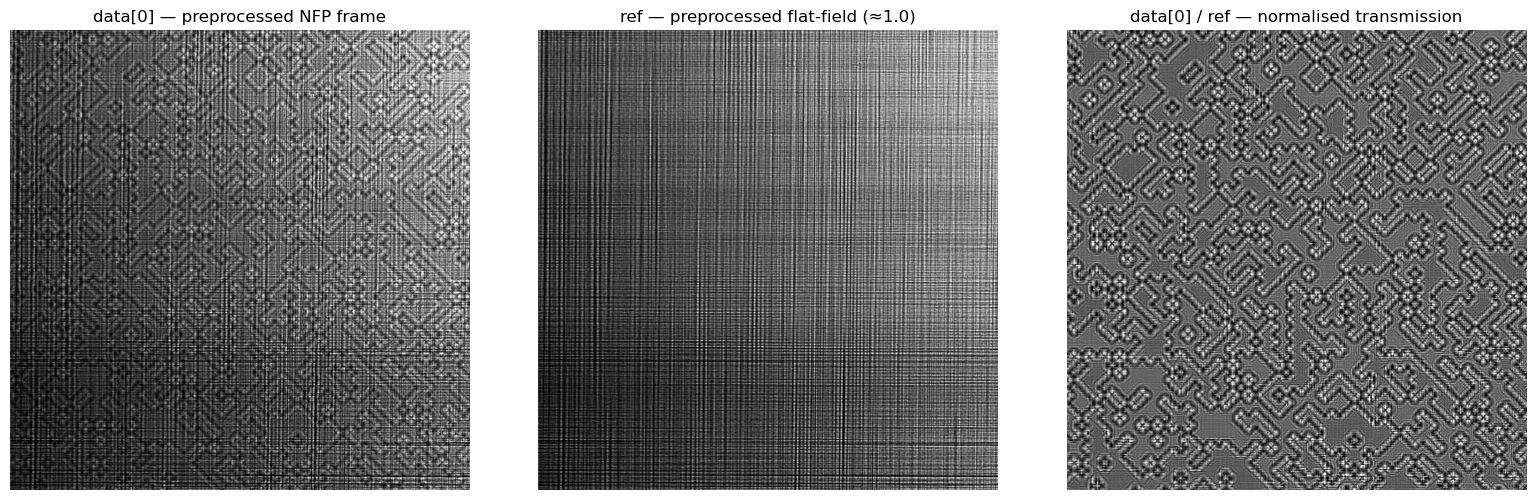

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(data[0], cmap='gray',
               vmin=np.percentile(data[0], 1), vmax=np.percentile(data[0], 99))
axes[0].set_title('data[0] — preprocessed NFP frame')
axes[0].axis('off')

axes[1].imshow(ref, cmap='gray',
               vmin=np.percentile(ref, 1), vmax=np.percentile(ref, 99))
axes[1].set_title('ref — preprocessed flat-field (≈1.0)')
axes[1].axis('off')

rdata0 = data[0] / (ref + 1e-6)
axes[2].imshow(rdata0, cmap='gray',
               vmin=np.percentile(rdata0, 1), vmax=np.percentile(rdata0, 99))
axes[2].set_title('data[0] / ref — normalised transmission')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## Figure out the scan positions

In [6]:
def my_phase_corr(d1, d2):
    """Integer-pixel phase cross-correlation between two 2D frames.
    Returns the NEGATIVE of the shift of d2 relative to d1.
    i.e. if d2 = shift(d1, +s), this returns -s.
    Apply as: S(d1, -result) to align d1 with d2.
    """
    image_product = np.fft.fft2(d1) * np.fft.fft2(d2).conj()
    cc_image = np.fft.fftshift(np.fft.ifft2(image_product))
    ind = np.unravel_index(np.argmax(cc_image.real, axis=None), cc_image.real.shape)
    return np.subtract(ind, np.array(d1.shape) // 2)   # (row_shift, col_shift)


def S(psi, p):
    """Subpixel Fourier-domain shift of a batch of complex frames (GPU).

    psi : (nframes, ny, nx) complex64
    p   : (nframes, 2) float32 — [row_shift, col_shift] in pixels
    Returns shifted frames on CPU (complex64).
    """
    psi = cp.array(psi)
    p   = cp.array(p)
    nb  = psi.shape[-1]
    # frequency axes for padded (2n × 2n) array
    x = cp.fft.fftfreq(2 * nb).astype('float32')
    [y, x] = cp.meshgrid(x, x)
    psi = cp.pad(psi, ((0, 0), (nb // 2, nb // 2), (nb // 2, nb // 2)))
    # phase ramp: e^{-2πi(f_y·p_y + f_x·p_x)}
    pp  = np.exp(-2 * np.pi * 1j * (
              y * p[:, 1, None, None] + x * p[:, 0, None, None]
          )).astype('complex64')
    res = np.fft.ifft2(pp * np.fft.fft2(psi))
    res = res[:, nb // 2 : -nb // 2, nb // 2 : -nb // 2]  # unpad
    return res.get()

In [7]:
rdata           = data / (ref + 1e-6)   # (324, 2048, 2048), normalised intensity (removed probe)
rdatat          = rdata.copy()

shifts_relative = np.zeros((npos, 2), dtype='float32')  # (324, 2)

for k in range(0, npos - 1):
    # For each k, correlate rdata[k] vs rdata[k+1] to get relative shift.
    shifts_relative[k] = my_phase_corr(rdata[k], rdata[k + 1])

    # Shift frame k by accumulated offset and measure residual in central region
    rdatat[k:k+1] = S(rdata[k:k+1].astype('complex64'), -shifts_relative[k:k+1]).real

    # Check the center and calculate the residual error, if it is large, there may be error in correlation.
    dif = rdatat[k] - rdatat[k + 1]
    c, w = n // 2, n // 16
    nn  = np.linalg.norm(dif[c-w:c+w, c-w:c+w])
    if nn > 80:
        print(f'  WARNING k={k}: residual nn={nn:.1f}')

    if k % 50 == 0:
        print(f'  k={k:3d}  rel_shift={shifts_relative[k]}  residual={nn:.2f}')

print(f'Cross-correlation done. shifts_relative: {shifts_relative.shape}')

  k=  0  rel_shift=[ -6. 434.]  residual=73.78
  k= 50  rel_shift=[ 78. 269.]  residual=72.79
  k=100  rel_shift=[  59. -179.]  residual=61.75
  k=150  rel_shift=[-55. 346.]  residual=70.64
  k=200  rel_shift=[-138. -444.]  residual=70.01
  k=250  rel_shift=[ -67. -357.]  residual=68.31
  k=300  rel_shift=[-117.  -80.]  residual=62.19
Cross-correlation done. shifts_relative: (324, 2)


Last 5 shifts
[[2210. 1054.]
 [2277. 1654.]
 [2329. 2025.]
 [2329. 2025.]
 [2211. 2350.]]


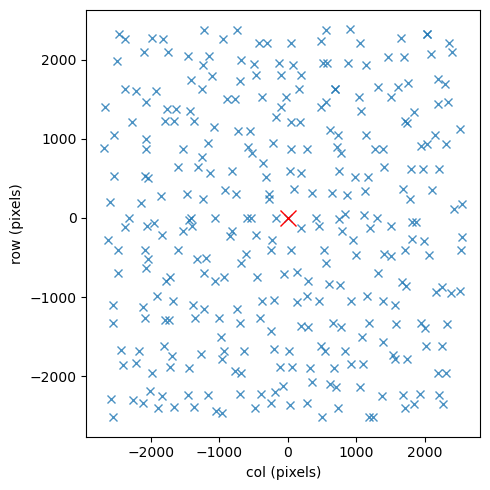

In [8]:
# Integrate relative shifts from anchor frame ipos = 171
#
# shifts_relative[k] ≈ pos[k+1] - pos[k]   (shift of frame k+1 relative to k)
#
# For k < ipos:  shifts_new[k] = sum_{j=k}^{ipos-1} shifts_relative[j] ≈ pos[ipos] - pos[k]
# For k = ipos:  shifts_new[ipos] = 0                    (anchor, by definition)
# For k > ipos:  shifts_new[k] = -sum_{j=ipos}^{k-1} shifts_relative[j] ≈ pos[ipos] - pos[k]
#
# Result: shifts_new[k] = pos[ipos] - pos[k]  → all positions relative to anchor.
# Stage 1d centres these with (min+max)/2 to place the FOV at the reconstruction origin.
ipos = npos // 2 + 9   # = 171  (near center)
shifts_new = np.zeros_like(shifts_relative)

for k in range(ipos):
    shifts_new[k] = np.sum(shifts_relative[k:ipos], axis=0)
shifts_new[ipos] = 0               # anchor frame: reference position (pos_ipos − pos_ipos = 0)
for k in range(ipos + 1, npos):
    shifts_new[k] = np.sum(-shifts_relative[ipos:k], axis=0)

print('Last 5 shifts')
print(shifts_new[-5:])

fig, axes = plt.subplots(1, 1, figsize=(5, 5))
axes.plot(shifts_new[:, 1], shifts_new[:, 0], 'x', label='xcorr (refined)',  alpha=0.8)
axes.plot(shifts_new[ipos, 1], shifts_new[ipos, 0], 'rx', ms=12, label=f'anchor frame {ipos} (origin)')
axes.set_xlabel('col (pixels)'); axes.set_ylabel('row (pixels)')
plt.tight_layout()
plt.show()

## Save preprocessed data and estimated shifts

In [9]:
with h5py.File(fname_ca, 'a') as fid:
    for key in ['/exchange/shifts', '/exchange/pdata', '/exchange/pref']:
        if key in fid:
            del fid[key]
    fid.create_dataset('/exchange/shifts', data=shifts_new.astype('float32'))  # (324, 2)
    fid.create_dataset('/exchange/pdata',  data=data)                          # (324, 2048, 2048)
    fid.create_dataset('/exchange/pref',   data=ref)                           # (2048, 2048)

print(f'Appended to {fname_ca}:')
print(f'  /exchange/shifts : {shifts_new.shape}  row=[{shifts_new[:,0].min():.1f},{shifts_new[:,0].max():.1f}]  col=[{shifts_new[:,1].min():.1f},{shifts_new[:,1].max():.1f}] px')
print(f'  /exchange/pdata  : {data.shape}')
print(f'  /exchange/pref   : {ref.shape}')

Appended to /data3/cekmekci/AtomiumS2_coded/nfp/data_nfp.h5:
  /exchange/shifts : (324, 2)  row=[-2521.0,2384.0]  col=[-2676.0,2544.0] px
  /exchange/pdata  : (324, 2048, 2048)
  /exchange/pref   : (2048, 2048)
